# Tópico 4 - FFT (Fast Fourier Transform)

## Visão Geral e Objetivos
Neste notebook, investigamos a **Transformada Rápida de Fourier (FFT)** e seu impacto na eficiência computacional em relação à **Transformada Discreta de Fourier (DFT)** direta. Os objetivos principais são:
1. **Conceituação da FFT**: Compreender que a FFT não é uma nova transformada, mas sim um algoritmo otimizado para computar a DFT aproveitando a simetria e periodicidade dos fatores de rotação $W_N^{kn}$.
2. **Equivalência Matemática**: Implementar a DFT direta $O(N^2)$ e comparar seus resultados numéricos com a função `numpy.fft.fft()` para demonstrar que ambos os métodos produzem resultados equivalentes.
3. **Análise de Complexidade Computacional**: Medir o tempo de execução para diferentes tamanhos de sequência $N$ e evidenciar experimentalmente a transição de complexidade de $O(N^2)$ para $O(N \log_2 N)$.
4. **Gerenciamento de Imagens**: Exportar os gráficos comparativos diretamente para o diretório local de simulação.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Implementação da DFT Direta e Validação com a FFT

A equação da DFT direta requer $N^2$ multiplicações complexas e $N(N-1)$ adições complexas:
$$X[k] = \sum_{n=0}^{N-1} x[n] e^{-j \frac{2\pi}{N} k n}, \quad k = 0, 1, \dots, N-1$$

Abaixo, definimos a função da DFT direta e a comparamos com a função `np.fft.fft()` para um sinal composto de $N = 64$ amostras.

Erro máximo absoluto entre DFT Direta e FFT (N=64): 3.46e-13


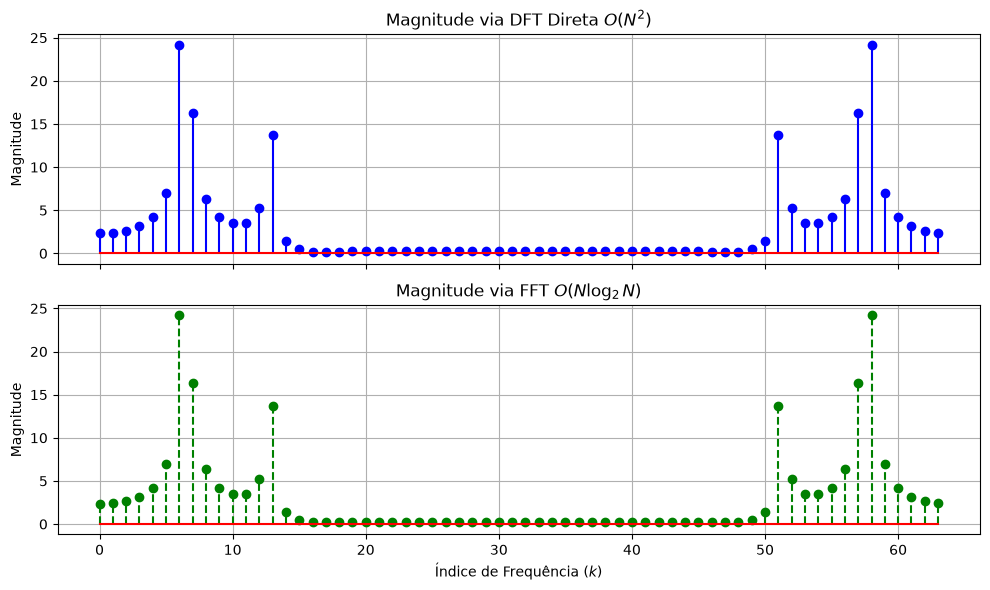

In [2]:
def dft_direta(x):
    """Calcula a DFT de maneira direta utilizando produto matricial O(N^2)."""
    N = len(x)
    n = np.arange(N)
    k = np.arange(N)
    n_mat, k_mat = np.meshgrid(n, k)
    W_N = np.exp(-1j * 2 * np.pi * k_mat * n_mat / N)
    return np.dot(W_N, x)

# 1. Geração de um sinal de teste com N = 64 amostras
N = 64
n = np.arange(N)
sinal_teste = np.sin(0.2 * np.pi * n) + 0.5 * np.cos(0.4 * np.pi * n)

# 2. Cálculo da transformada via ambos os métodos
X_dft = dft_direta(sinal_teste)
X_fft = np.fft.fft(sinal_teste)

# 3. Avaliação da equivalência numérica (Erro Máximo Absoluto)
erro_maximo = np.max(np.abs(X_dft - X_fft))
print(f"Erro máximo absoluto entre DFT Direta e FFT (N={N}): {erro_maximo:.2e}")

# 4. Plotagem comparativa da magnitude
fig1, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.stem(n, np.abs(X_dft), linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title(r'Magnitude via DFT Direta $O(N^2)$')
ax1.set_ylabel('Magnitude')
ax1.grid(True)

ax2.stem(n, np.abs(X_fft), linefmt='g--', markerfmt='go', basefmt='r-')
ax2.set_title(r'Magnitude via FFT $O(N \log_2 N)$')
ax2.set_xlabel('Índice de Frequência ($k$)')
ax2.set_ylabel('Magnitude')
ax2.grid(True)

plt.tight_layout()
fig1.savefig("grafico_comparacao_dft_fft.png")
plt.show()

## 2. Benchmark de Tempo de Execução: DFT Direta vs. FFT

Para evidenciar a importância computacional da FFT (algoritmos baseados no agrupamento par/ímpar de Cooley-Tukey), realizamos um experimento de medição de tempo de processamento (*benchmark*) variando o tamanho do sinal $N \in \{32, 64, 128, 256, 512, 1024, 2048\}$.

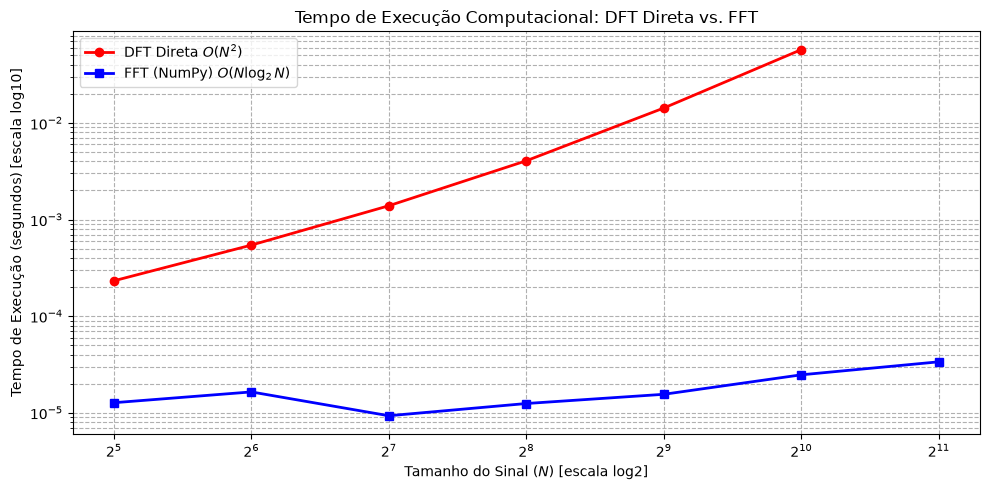

In [3]:
# Valores de N para o teste de desempenho
valores_N = [32, 64, 128, 256, 512, 1024, 2048]
tempos_dft = []
tempos_fft = []

for N_i in valores_N:
    n_i = np.arange(N_i)
    sinal = np.sin(0.1 * np.pi * n_i) + np.cos(0.3 * np.pi * n_i)
    
    # 1. Medição do tempo da DFT Direta (limita-se a N <= 1024 para evitar demoras excessivas)
    if N_i <= 1024:
        t0 = time.perf_counter()
        _ = dft_direta(sinal)
        t1 = time.perf_counter()
        tempos_dft.append(t1 - t0)
    else:
        tempos_dft.append(None)
    
    # 2. Medição do tempo da FFT (média de 100 execuções para maior precisão)
    t0 = time.perf_counter()
    for _ in range(100):
        _ = np.fft.fft(sinal)
    t1 = time.perf_counter()
    tempos_fft.append((t1 - t0) / 100.0)

# 3. Plotagem em escala logarítmica
fig2, ax = plt.subplots(figsize=(10, 5))

# Filtragem de valores para a curva da DFT
valid_N_dft = [N_i for N_i, t in zip(valores_N, tempos_dft) if t is not None]
valid_t_dft = [t for t in tempos_dft if t is not None]

ax.plot(valid_N_dft, valid_t_dft, 'o-', color='red', linewidth=2, label=r'DFT Direta $O(N^2)$')
ax.plot(valores_N, tempos_fft, 's-', color='blue', linewidth=2, label=r'FFT (NumPy) $O(N \log_2 N)$')

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_title('Tempo de Execução Computacional: DFT Direta vs. FFT')
ax.set_xlabel('Tamanho do Sinal ($N$) [escala log2]')
ax.set_ylabel('Tempo de Execução (segundos) [escala log10]')
ax.grid(True, which="both", ls="--")
ax.legend()

plt.tight_layout()
fig2.savefig("grafico_tempo_execucao_fft.png")
plt.show()

## 3. Conclusões da Investigação da FFT
- **Precisão Numérica**: A diferença absoluta entre os resultados da DFT direta e da FFT é da ordem de $10^{-15}$, o que confirma a exata equivalência matemática entre os dois métodos.
- **Redução de Complexidade**: Para um sinal de $N = 1024$ pontos, a DFT direta requer cerca de $N^2 \approx 10^6$ operações, enquanto a FFT exige cerca de $N \log_2 N \approx 1024 \times 10 \approx 10^4$ operações.
- **Ganho Computacional**: O gráfico em escala logarítmica evidencia que o tempo de execução da DFT direta cresce quadraticamente, enquanto o tempo da FFT permanece extremamente baixo e viabiliza o processamento espectral em tempo real.